# Desigualdade de gênero no mercado de trabalho no estado de São Paulo
**Integrantes:** Felipe Freitas e Wanessa Gonçalves  
**Disciplina:** Introdução à Ciência de Dados — TSI, 5º semestre — Centro Universitário Senac  
**Base:** IBGE, PNAD Contínua, 4º trimestre de 2025.  

**Questão:** Quais diferenças existem entre mulheres e homens em participação entre os ocupados, rendimento habitual e setor econômico?  

> **Reprodução:** no Google Colab, execute as células em ordem. Envie o arquivo original `PNADC_042025.zip` quando solicitado. Os demais downloads são automáticos. Os números representam estimativas amostrais ponderadas, não contagens da amostra ou provas de causalidade.

## 1. Bibliotecas e preparação

## 2. Base e documentação
Arquivo de microdados: [PNAD Contínua trimestral — 2025](https://ftp.ibge.gov.br/Trabalho_e_Rendimento/Pesquisa_Nacional_por_Amostra_de_Domicilios_continua/Trimestral/Microdados/2025/). A documentação define a **posição inicial** e o **tamanho** de cada variável em um TXT de largura fixa. Se o ZIP já estiver em `/content`, o upload será ignorado.

In [37]:
from pathlib import Path
import requests
import zipfile

url = (
    "https://ftp.ibge.gov.br/Trabalho_e_Rendimento/"
    "Pesquisa_Nacional_por_Amostra_de_Domicilios_continua/"
    "Trimestral/Microdados/2025/PNADC_042025.zip"
)

destino = Path("/content/PNADC_042025.zip")
temporario = Path("/content/PNADC_download.tmp")

print("Baixando diretamente do IBGE...")

try:
    with requests.get(url, stream=True, timeout=120) as resposta:
        resposta.raise_for_status()

        with open(temporario, "wb") as arquivo:
            for bloco in resposta.iter_content(
                chunk_size=1024 * 1024
            ):
                if bloco:
                    arquivo.write(bloco)

    tamanho = temporario.stat().st_size / 1024**2
    valido = zipfile.is_zipfile(temporario)

    print(f"Tamanho baixado: {tamanho:.2f} MB")
    print("ZIP válido:", valido)

    if valido:
        temporario.replace(destino)
        print("Arquivo corrigido com sucesso!")
    else:
        print("O download ainda está incompleto.")
        temporario.unlink(missing_ok=True)

except Exception as erro:
    print("Falha no download:", erro)


Baixando diretamente do IBGE...
Tamanho baixado: 212.24 MB
ZIP válido: True
Arquivo corrigido com sucesso!


In [38]:
from pathlib import Path
import zipfile

# Arquivo enviado pela aba de pastas do Colab
caminho_zip = Path("PNADC_042025.zip")

# Verificar se o arquivo existe
if not caminho_zip.exists():
    raise FileNotFoundError(
        "Arquivo não encontrado. "
        "Envie PNADC_042025.zip pela aba Arquivos do Colab."
    )

# Verificar se o ZIP é válido
if not zipfile.is_zipfile(caminho_zip):
    raise ValueError(
        "O arquivo ZIP está inválido ou incompleto."
    )

# Localizar o TXT dentro do ZIP
with zipfile.ZipFile(caminho_zip, "r") as z:
    nome_txt = next(
        (
            nome for nome in z.namelist()
            if nome.endswith("PNADC_042025.txt")
        ),
        None
    )

    if nome_txt is None:
        raise ValueError(
            "Arquivo TXT não encontrado dentro do ZIP."
        )

print("Dataset encontrado com sucesso!")
print("Arquivo:", caminho_zip.name)
print("Microdados:", nome_txt)

# Mantém os nomes usados pelas próximas células
micro_zip = caminho_zip


Dataset encontrado com sucesso!
Arquivo: PNADC_042025.zip
Microdados: PNADC_042025.txt


In [39]:
doc_zip = BASE / 'dicionario_ibge.zip'
URL_DOC = ('https://ftp.ibge.gov.br/Trabalho_e_Rendimento/'
           'Pesquisa_Nacional_por_Amostra_de_Domicilios_continua/'
           'Trimestral/Microdados/Documentacao/Dicionario_e_input_20221031.zip')
if not (doc_zip.exists() and zipfile.is_zipfile(doc_zip)):
    r = requests.get(URL_DOC, timeout=180)
    r.raise_for_status()
    doc_zip.write_bytes(r.content)
if not zipfile.is_zipfile(doc_zip):
    raise ValueError('Documentação não é um ZIP válido.')
with zipfile.ZipFile(doc_zip) as z:
    excel_nome = next((x for x in z.namelist() if x.lower().endswith(('.xlsx','.xls'))), None)
    if not excel_nome: raise ValueError('Dicionário em Excel não encontrado.')
    dicionario = pd.read_excel(io.BytesIO(z.read(excel_nome)), header=None)
layout = dicionario.iloc[:,[0,1,2,4]].copy()
layout.columns = ['Posicao','Tamanho','Variavel','Descricao']
layout['Posicao'] = pd.to_numeric(layout['Posicao'], errors='coerce')
layout['Tamanho'] = pd.to_numeric(layout['Tamanho'], errors='coerce')
layout = layout.dropna(subset=['Posicao','Tamanho','Variavel'])
layout['Variavel'] = layout['Variavel'].astype(str).str.strip()
print('Variáveis identificadas:', len(layout))

Variáveis identificadas: 420


## 3. Pré-processamento
Selecionamos apenas registros com código da UF `35` (São Paulo) e extraímos as variáveis diretamente por posição fixa, **preservando a ordem dos registros**. Valores em branco tornam-se ausentes. A atividade econômica e a escolaridade são categóricas; rendimento, idade e peso são numéricos.

In [40]:
codigos = ['UF','V1028','V2007','V2009','VD3004','VD4002','VD4010','VD4016','VD4019']
l = layout[layout['Variavel'].isin(codigos)].drop_duplicates('Variavel').set_index('Variavel')
faltantes = set(codigos) - set(l.index)
if faltantes: raise ValueError(f'Variáveis não encontradas no dicionário: {faltantes}')
intervalos = {v: (int(l.loc[v,'Posicao'])-1, int(l.loc[v,'Posicao'])-1+int(l.loc[v,'Tamanho'])) for v in codigos}
registros = []
with zipfile.ZipFile(micro_zip) as z:
    with z.open(nome_txt) as arq:
        for linha in arq:
            if linha[5:7] != b'35': continue
            registros.append({v: linha[a:f].decode('latin-1').strip() for v,(a,f) in intervalos.items()})
dados_sp = pd.DataFrame(registros, columns=codigos).replace('', pd.NA)
for v in ['V1028','V2009','VD4016','VD4019']:
    dados_sp[v] = pd.to_numeric(dados_sp[v], errors='coerce')
print('Registros da amostra paulista:',len(dados_sp))
print('Não preenchidos em cada variável:')
display(dados_sp.isna().sum().to_frame('Ausentes'))
display(dados_sp.head())

Registros da amostra paulista: 38483
Não preenchidos em cada variável:


,Ausentes
UF,0
V1028,0
V2007,0
V2009,0
VD3004,1838
VD4002,17797
VD4010,18761
VD4016,18940
VD4019,18939


,UF,V1028,V2007,V2009,VD3004,VD4002,VD4010,VD4016,VD4019
0,35,1708.074158,1,60,7,2,<NA>,NaN,NaN
1,35,1708.074158,2,55,7,1,09,6000.0,6000.0
2,35,1708.074158,1,21,7,1,07,2500.0,2500.0
3,35,1161.462400,2,42,7,1,09,2500.0,2500.0
4,35,1982.648057,2,24,5,2,<NA>,NaN,NaN


## 4. Indicador 1 — Participação por gênero entre pessoas ocupadas
**Fórmula:** soma dos pesos de pessoas ocupadas de determinado gênero ÷ soma dos pesos de todas as pessoas ocupadas com gênero conhecido × 100. Não é taxa de ocupação da população geral.

,Participação (%)
Genero,
Homens,55.22
Mulheres,44.78


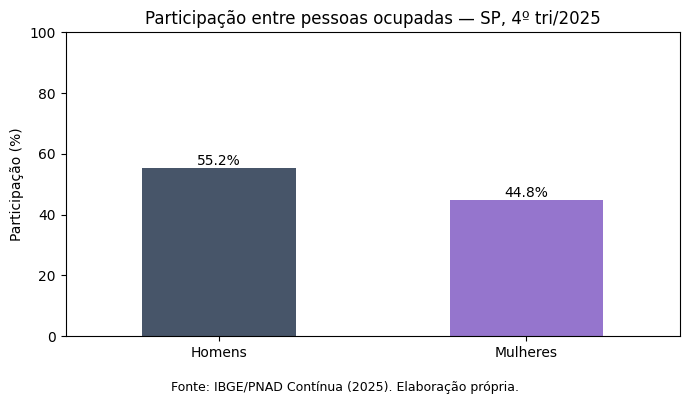

In [48]:
ocupados = dados_sp[(dados_sp['VD4002']=='1') & (dados_sp['V2007'].isin(['1','2'])) & (dados_sp['V1028']>0)].copy()
ocupados['Genero'] = ocupados['V2007'].map({'1':'Homens','2':'Mulheres'})
pesos_genero = ocupados.groupby('Genero')['V1028'].sum().reindex(['Homens','Mulheres'])
percentuais = 100*pesos_genero/pesos_genero.sum()
display(percentuais.round(2).rename('Participação (%)'))
fig,ax=plt.subplots(figsize=(7,4))
percentuais.plot.bar(ax=ax, color=['#475569','#9575CD'],rot=0)
ax.set(title='Participação entre pessoas ocupadas — SP, 4º tri/2025',xlabel='',ylabel='Participação (%)',ylim=(0,100))
for i,v in enumerate(percentuais):ax.text(i,v+1,f'{v:.1f}%',ha='center')
fig.text(.5,.01,'Fonte: IBGE/PNAD Contínua (2025). Elaboração própria.',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.05,1,1]);fig.savefig(SAIDA/'01_participacao.png',dpi=250,bbox_inches='tight');plt.show()

## 5. Indicador 2 — Rendimento médio habitual do trabalho principal
**Fórmula:** média ponderada = soma(rendimento × peso) ÷ soma(peso), considerando ocupados com rendimento habitual positivo (`VD4016`). **Diferença percentual:** (média homens − média mulheres) ÷ média homens × 100. Não é remuneração por hora nem comparação de salários para a mesma função.

,Rendimento médio (R$)
Genero,
Homens,4723.03
Mulheres,3599.50


Diferença absoluta: R$ 1,123.53 | Diferença percentual: 23.79%


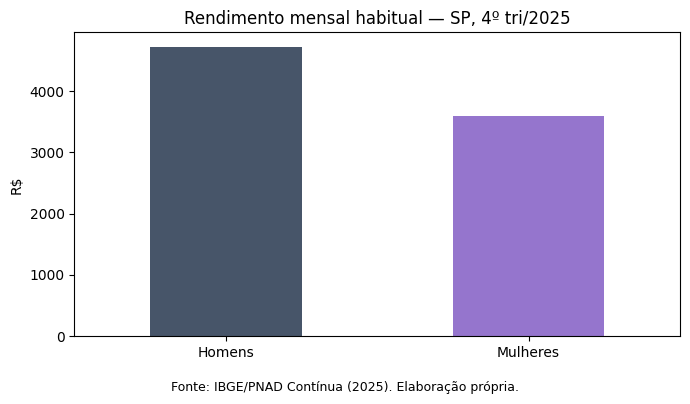

In [42]:
salarios = ocupados.dropna(subset=['VD4016']).query('VD4016 > 0').copy()
def media_ponderada(g,variavel='VD4016'):
    return np.average(g[variavel].to_numpy(float), weights=g['V1028'].to_numpy(float))
rendimento_medio = salarios.groupby('Genero').apply(media_ponderada,include_groups=False).reindex(['Homens','Mulheres'])
dif_abs = rendimento_medio['Homens']-rendimento_medio['Mulheres']
dif_pct = 100*dif_abs/rendimento_medio['Homens']
display(rendimento_medio.round(2).rename('Rendimento médio (R$)'))
print(f'Diferença absoluta: R$ {dif_abs:,.2f} | Diferença percentual: {dif_pct:.2f}%')
fig,ax=plt.subplots(figsize=(7,4));rendimento_medio.plot.bar(ax=ax,color=['#475569','#9575CD'],rot=0)
ax.set(title='Rendimento mensal habitual — SP, 4º tri/2025',xlabel='',ylabel='R$')
fig.text(.5,.01,'Fonte: IBGE/PNAD Contínua (2025). Elaboração própria.',ha='center',fontsize=9)
fig.tight_layout(rect=[0,.05,1,1]);fig.savefig(SAIDA/'02_rendimento.png',dpi=250,bbox_inches='tight');plt.show()

## 6. Indicador 3 — Participação por gênero em cada setor econômico
**Fórmula:** peso ponderado do gênero em um setor ÷ peso ponderado de todos os trabalhadores do setor × 100. Registros sem grupamento de atividade ficam fora desta comparação. Os códigos `VD4010` são apresentados por grandes grupamentos.

Genero,Mulheres,Homens
Setor,,
Construção,5.94,94.06
"Transporte, armazenagem e correio",18.38,81.62
Agropecuária,19.41,80.59
Indústria geral,31.90,68.10
Atividades mal definidas,32.10,67.90
"Administração pública, defesa e seguridade social",40.08,59.92
Comércio e reparação,42.86,57.14
"Informação, comunicação, finanças e serviços profissionais",44.24,55.76
Alojamento e alimentação,52.15,47.85


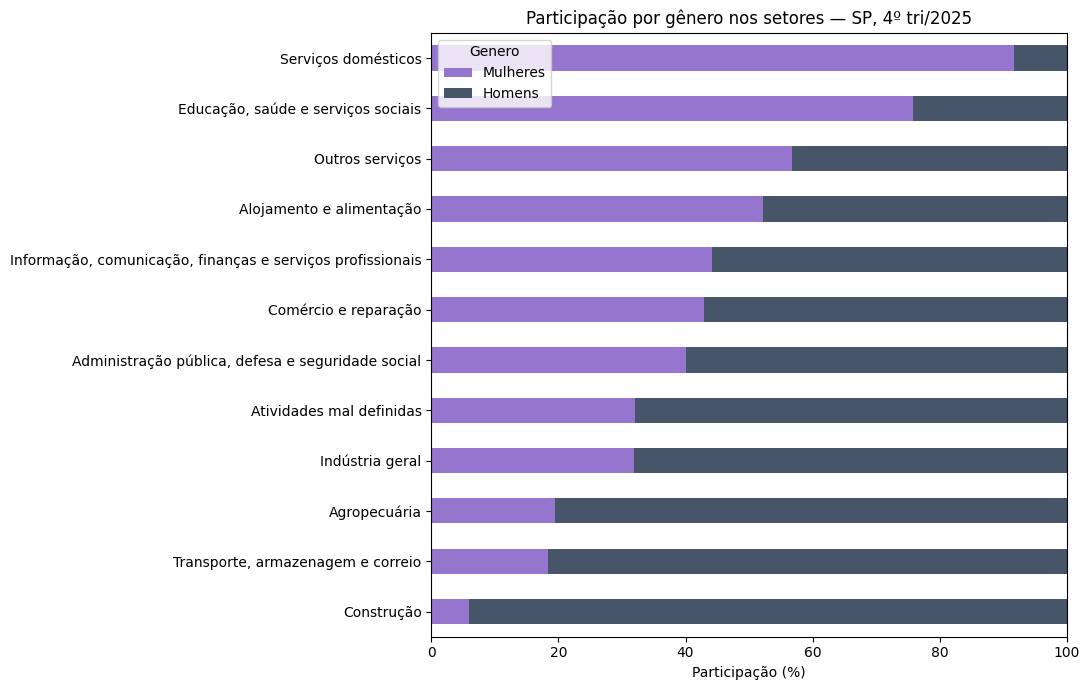

In [47]:
setores = {
'01':'Agropecuária','02':'Indústria geral','03':'Construção','04':'Comércio e reparação',
'05':'Transporte, armazenagem e correio','06':'Alojamento e alimentação',
'07':'Informação, comunicação, finanças e serviços profissionais',
'08':'Administração pública, defesa e seguridade social',
'09':'Educação, saúde e serviços sociais','10':'Outros serviços',
'11':'Serviços domésticos','12':'Atividades mal definidas'}
base_setores=ocupados[ocupados['VD4010'].isin(setores)].copy()
base_setores['Setor']=base_setores['VD4010'].map(setores)
tabela_setores=base_setores.pivot_table(index='Setor',columns='Genero',values='V1028',aggfunc='sum',fill_value=0)
percentuais_setores=tabela_setores.div(tabela_setores.sum(axis=1),axis=0).mul(100).reindex(columns=['Mulheres','Homens'],fill_value=0)
percentuais_setores=percentuais_setores.sort_values('Mulheres')
display(percentuais_setores.round(2))
ax=percentuais_setores.plot.barh(stacked=True,figsize=(11,7),color=['#9575CD','#475569'])
ax.set(title='Participação por gênero nos setores — SP, 4º tri/2025',xlabel='Participação (%)',ylabel='',xlim=(0,100))
plt.tight_layout();plt.savefig(SAIDA/'03_setores.png',dpi=250,bbox_inches='tight');plt.show()

## 7. Análise complementar — Escolaridade e idade
Verificamos níveis educacionais e faixas de idade para contextualizar as diferenças salariais. Valores de subgrupos menores podem ser instáveis e não são acompanhados aqui de intervalos de confiança.

Genero,Homens,Mulheres
Escolaridade,,
Sem instrução/menos de 1 ano,2939.12,2314.82
Fundamental incompleto,2647.89,1626.09
Fundamental completo,3524.75,1913.04
Médio incompleto,2480.03,1753.76
Médio completo,3376.50,2344.89
Superior incompleto,4287.62,2741.96
Superior completo,8849.56,6043.85


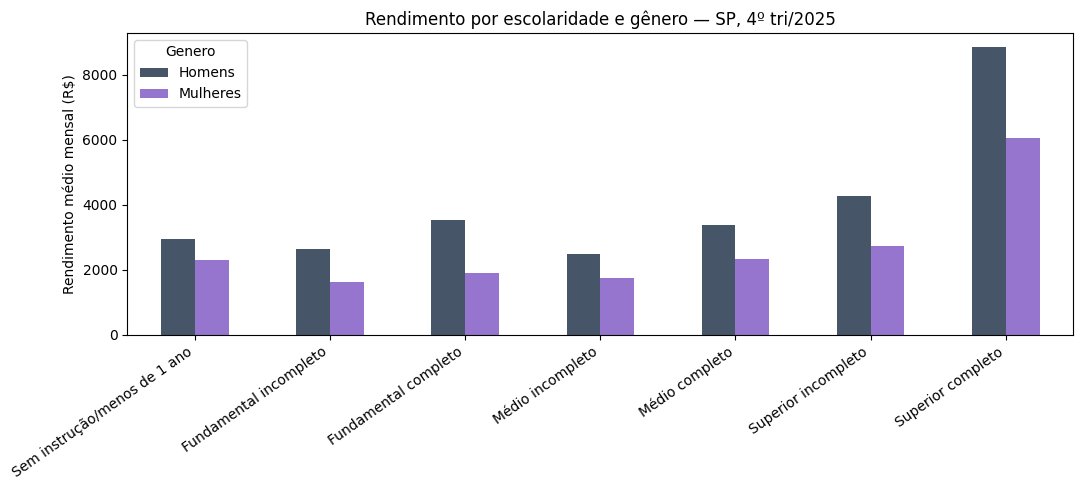

Genero,Homens,Mulheres
Faixa_Etaria,,
14 a 24,2345.67,1928.25
25 a 34,4543.50,3527.82
35 a 44,5359.05,4148.22
45 a 54,5315.25,4099.21
55 a 64,5069.23,3352.92
65 ou mais,5414.70,3874.12


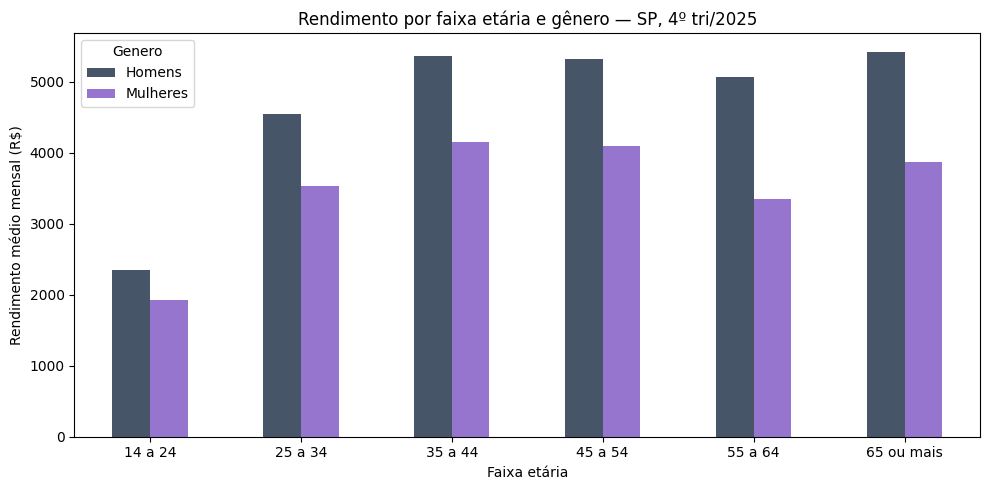

In [44]:
niveis={'1':'Sem instrução/menos de 1 ano','2':'Fundamental incompleto','3':'Fundamental completo',
'4':'Médio incompleto','5':'Médio completo','6':'Superior incompleto','7':'Superior completo'}
dados_escolaridade=salarios[salarios['VD3004'].isin(niveis)].copy()
dados_escolaridade['Escolaridade']=dados_escolaridade['VD3004'].map(niveis)
resultado_escolaridade=dados_escolaridade.groupby(['Escolaridade','Genero']).apply(media_ponderada,include_groups=False).unstack().reindex(list(niveis.values()))
display(resultado_escolaridade.round(2))
ax=resultado_escolaridade.plot.bar(figsize=(11,5),color=['#475569','#9575CD'])
ax.set(title='Rendimento por escolaridade e gênero — SP, 4º tri/2025',xlabel='',ylabel='Rendimento médio mensal (R$)')
plt.xticks(rotation=35,ha='right');plt.tight_layout();plt.savefig(SAIDA/'04_escolaridade.png',dpi=250,bbox_inches='tight');plt.show()

faixas=[14,25,35,45,55,65,float('inf')]
nomes_faixas=['14 a 24','25 a 34','35 a 44','45 a 54','55 a 64','65 ou mais']
dados_idade=salarios.copy()
dados_idade['Faixa_Etaria']=pd.cut(dados_idade['V2009'],bins=faixas,labels=nomes_faixas,right=False)
resultado_idade=dados_idade.dropna(subset=['Faixa_Etaria']).groupby(['Faixa_Etaria','Genero'],observed=True).apply(media_ponderada,include_groups=False).unstack().reindex(nomes_faixas)
display(resultado_idade.round(2))
ax=resultado_idade.plot.bar(figsize=(10,5),color=['#475569','#9575CD'])
ax.set(title='Rendimento por faixa etária e gênero — SP, 4º tri/2025',xlabel='Faixa etária',ylabel='Rendimento médio mensal (R$)')
plt.xticks(rotation=0);plt.tight_layout();plt.savefig(SAIDA/'05_faixa_etaria.png',dpi=250,bbox_inches='tight');plt.show()

## 8. Exportação dos resultados
Geramos um Excel com cinco tabelas e um ZIP com os cinco gráficos, para inserir no relatório.

In [46]:
with pd.ExcelWriter(SAIDA/'indicadores_genero_sp.xlsx') as writer:
    percentuais.to_frame('Participacao_percentual').to_excel(writer,sheet_name='Participacao')
    rendimento_medio.to_frame('Rendimento_medio').to_excel(writer,sheet_name='Rendimento')
    percentuais_setores.to_excel(writer,sheet_name='Setores')
    resultado_escolaridade.to_excel(writer,sheet_name='Escolaridade')
    resultado_idade.to_excel(writer,sheet_name='Faixa_etaria')
with zipfile.ZipFile(BASE/'graficos_icd.zip','w') as z:
    for p in sorted(SAIDA.glob('*.png')):z.write(p,arcname=p.name)
print('Resultados em:', SAIDA)
print('Gráficos compactados em:',BASE/'graficos_icd.zip')

Resultados em: /content/resultados_icd
Gráficos compactados em: /content/graficos_icd.zip


## 9. Interpretação, limitações e proposta de dashboard

**Pergunta 4 — O que os dados indicam?** Os três indicadores descrevem diferenças entre os gêneros na composição das pessoas ocupadas, na média mensal habitual dos rendimentos do trabalho principal e na composição dos setores econômicos. Interpretar os valores mostrados nas tabelas acima antes de redigir a conclusão final. Nenhuma diferença descritiva demonstra causalidade ou discriminação individual por si só.

**Pergunta 5 — Que tipo de aplicação seria útil?** Propomos uma dashboard com cartões de participação feminina, rendimento por gênero e diferença percentual; barras empilhadas por setor; e comparativos por escolaridade e idade. Filtros por período só devem ser oferecidos após incluir microdados de mais períodos. Uma dashboard ajuda a comparar indicadores rapidamente e discutir prioridades de investigação e políticas públicas.

**Limitações:** PNAD Contínua é pesquisa amostral e requer o uso de pesos, aplicado aqui. Para erros-padrão, significância e intervalos de confiança, também deve ser considerado seu desenho amostral complexo. O rendimento é mensal habitual entre ocupados com valores positivos, e não uma medida de salário por hora ou de trabalhadores na mesma função. O recorte é o estado de São Paulo, não bairros ou municípios. A interpretação dos códigos deve seguir o dicionário correspondente ao arquivo de 2025.

**Referência:** IBGE. *Pesquisa Nacional por Amostra de Domicílios Contínua: microdados trimestrais, 4º trimestre de 2025*. https://www.ibge.gov.br/estatisticas/sociais/trabalho/9173-pnad-continua.html